**Homework 2**

In [80]:
import pandas as pd
import numpy as np


df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')
df2 = df.copy()
#print(df.dtypes)

base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']

for c in df2.columns:
    if c not in base:
        del df2[c]

print(df2.dtypes)
print(df2.isnull().sum())

hp_median = df2.horsepower.median()
print('median horsepower: ', hp_median)

model_year               int64
engine_displacement      int64
horsepower             float64
vehicle_weight           int64
fuel_efficiency_mpg    float64
dtype: object
model_year               0
engine_displacement      0
horsepower             877
vehicle_weight           0
fuel_efficiency_mpg      0
dtype: int64
median horsepower:  254.0


count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: str


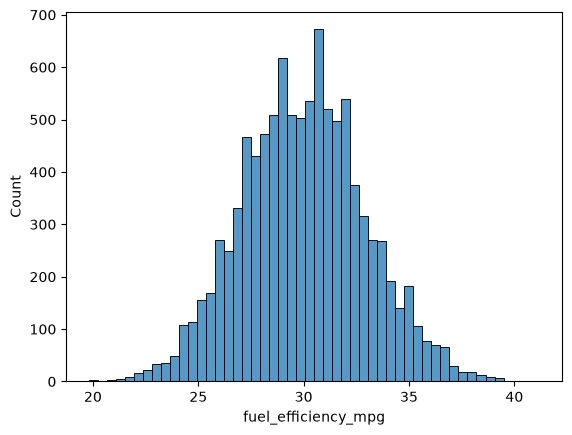

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.histplot(df2.fuel_efficiency_mpg, bins=50)

print(df.fuel_efficiency_mpg.describe().apply(lambda x: format(x, 'f')))

In [60]:
n = len(df2)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df2.iloc[idx[:n_train]]
df_val = df2.iloc[idx[n_train:n_train + n_val]]
df_test = df2.iloc[idx[n_train + n_val:]]

# target y
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values


del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']


Fill missing horsepower with 0

      model_year  engine_displacement  horsepower  vehicle_weight
6252        2015                 1900       239.0            3790
4684        1992                 2000       224.0            4380
1731        2022                 2330       286.0            4090
4742        1997                 2300         0.0            4150
4521        2001                 2340       269.0            4400
...          ...                  ...         ...             ...
7895        2018                 2280       242.0            4590
9590        1984                 2300         0.0            4240
7288        1989                 2240       255.0            4190
278         2020                 2430       254.0            4280
3252        1996                 2390       266.0            4220

[6000 rows x 4 columns]
2.19


<Axes: ylabel='Count'>

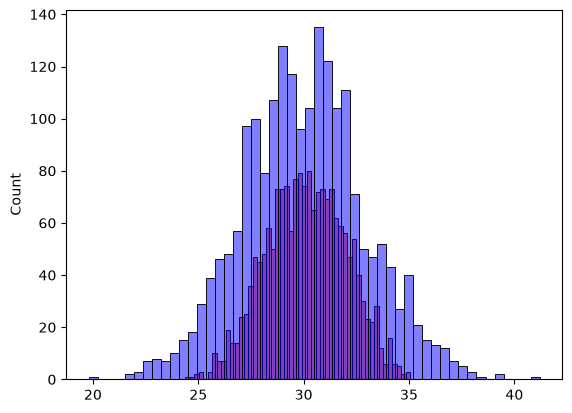

In [71]:
df_train = df2.iloc[idx[:n_train]]
del df_train['fuel_efficiency_mpg']

new_hp = df_train['horsepower'].fillna(0).values
df_train['horsepower'] = new_hp

print(df_train)

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)


w0, w = train_linear_regression(df_train, y_train)
#print(w0, w)


y_pred = w0 + df_val.dot(w)

score = rmse(y_val, y_pred)
print(round(score, 3))

sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_val, color='blue', alpha=0.5, bins=50)

Fill missing horsepower with mean

      model_year  engine_displacement  horsepower  vehicle_weight
6252        2015                 1900       239.0            3790
4684        1992                 2000       224.0            4380
1731        2022                 2330       286.0            4090
4742        1997                 2300       254.0            4150
4521        2001                 2340       269.0            4400
...          ...                  ...         ...             ...
7895        2018                 2280       242.0            4590
9590        1984                 2300       254.0            4240
7288        1989                 2240       255.0            4190
278         2020                 2430       254.0            4280
3252        1996                 2390       266.0            4220

[6000 rows x 4 columns]
2.186


<Axes: ylabel='Count'>

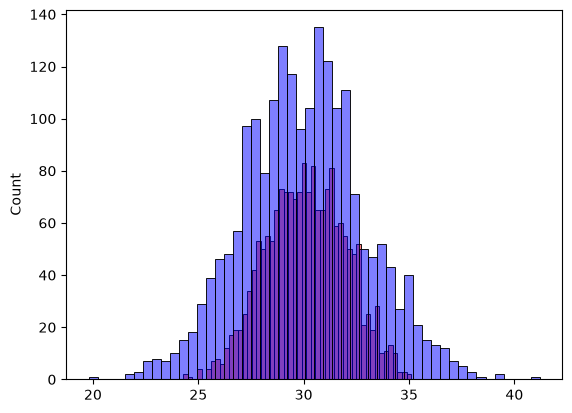

In [68]:
df_train = df2.iloc[idx[:n_train]]
del df_train['fuel_efficiency_mpg']

hp_median = df_train['horsepower'].median()
#print('median horsepower: ', hp_median)

new_hp = df_train['horsepower'].fillna(hp_median).values
df_train['horsepower'] = new_hp

print(df_train)

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)


w0, w = train_linear_regression(df_train, y_train)
#print(w0, w)


y_pred = w0 + df_val.dot(w)

score = rmse(y_val, y_pred)
print(round(score, 3))

sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_val, color='blue', alpha=0.5, bins=50)

Regularization and tuning r

In [76]:
df_train = df2.iloc[idx[:n_train]]
del df_train['fuel_efficiency_mpg']

new_hp = df_train['horsepower'].fillna(0).values
df_train['horsepower'] = new_hp


def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]



def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)


w0, w = train_linear_regression(df_train, y_train)
#print(w0, w)


for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = df_train
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = df_val
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, round(score, 4))


0 -153.88496188223502 2.1896
0.01 -148.3092124415433 2.1903
0.1 -111.83871039255934 2.2102
1 -32.33186596505726 2.3413
5 -7.772852209970626 2.4038
10 -3.987116415903798 2.4143
100 -0.40821964883327444 2.4244


Tuning seed values

In [81]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)


def split_dataset(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    return df_train, df_val, df_test


seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []

for seed in seeds:
    
    df_train, df_val, df_test = split_dataset(df2, seed)

    # target y
    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values
    y_test = df_test['fuel_efficiency_mpg'].values

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    new_hp = df_train['horsepower'].fillna(0).values
    df_train['horsepower'] = new_hp

    w0, w = train_linear_regression(df_train, y_train)
    y_pred = w0 + df_val.dot(w)

    score = rmse(y_val, y_pred)
    scores.append(score)
    print(round(score, 3))

stdev = np.std(scores)
print('std: ', round(stdev, 3))







2.249
2.203
2.181
2.2
2.189
2.235
2.258
2.198
2.201
2.206
std:  0.025


Combining train+validation sets, and training with regularization

In [91]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)


def split_dataset(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    return df_train, df_val, df_test


def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]




df_train, df_val, df_test = split_dataset(df2, 9)

# target y
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']


df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)
new_hp = df_full_train['horsepower'].fillna(0).values
df_full_train['horsepower'] = new_hp
#print(df_full_train)
y_full_train = np.concatenate([y_train, y_val])
#print(y_full_train)

w0, w = train_linear_regression_reg(df_full_train, y_full_train, r=0.001)
print(w0, w)

X_test = df_test
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
print(score)


-152.37535772502957 [ 0.10140402 -0.00135534 -0.00042645 -0.00401765]
2.238996596694746
